In [28]:
# this file uses a diagramatic approach to justify the decisions made in data.py where data is cleaned

# fixing metadata
import pandas as pd
import os 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

metadata_file_path = '../data/others/subject_metadata.xls'
metadata_df = pd.read_excel(metadata_file_path)

#Juc010 doesnt exist in raw dataset, fixing Ju study heights (cm to m)
metadata_df = metadata_df.drop(metadata_df[(metadata_df['Study'] == 'Ju') & (metadata_df['Group'] == 'CO') & (metadata_df['Subjnum'] == 10)].index)
metadata_df.loc[metadata_df['Study'] == 'Ju', 'Height (meters)'] /= 100
# change CO/PD to Co/Pt so it matches file names

metadata_df['Group'] = metadata_df['Group'].replace({'PD': 'Pt', 'CO':'Co'})

# checking raw data (walking files)
walking_file_path = '../data/processed'
rows = []
for file in sorted(os.listdir(walking_file_path)):
    if not file.endswith('csv'):
        continue
    walk = pd.read_csv(os.path.join(walking_file_path, file))
    time = walk.iloc[:, 0] #first col
    forces = walk.iloc[:, 1:] #remaining 18 col with forces
    rows.append({
        'file': file,
        'study': file[:2],
        'n_rows': len(walk),
        'duration_s': time.iloc[-1] - time.iloc[0],
        'has_nan': walk.isna().any().any(),
        'has_negative': (forces < 0).any().any(),
        'steady_100hz': np.allclose(np.diff(time), 0.01, atol=0.0002),
        # leading rows identical to the first row; 1 = no flat start
        'flat_start_rows': (forces != forces.iloc[0]).any(axis=1).to_numpy().argmax(),
    })
# ends up looking like [{'file': 'GaCo01_01.csv', 'study': 'Ga', 'n_rows': 12119, 'duration_s': 121.17, 'has_nan': False, 'has_negative': False, 'steady_100hz': True, 'flat_start_rows': 2}, ...]   # 306 dicts. so rows is 1D list with dicts
quality_df = pd.DataFrame(rows)
print(quality_df)


              file study  n_rows  duration_s  has_nan  has_negative  \
0    GaCo01_01.csv    Ga   12119    121.1715    False         False   
1    GaCo02_01.csv    Ga   12119    121.1715    False         False   
2    GaCo02_02.csv    Ga   12119    121.1715    False         False   
3    GaCo03_01.csv    Ga   12119    121.1715    False         False   
4    GaCo03_02.csv    Ga   12119    121.1715    False         False   
..             ...   ...     ...         ...      ...           ...   
301  SiPt36_01.csv    Si   12119    121.1715    False         False   
302  SiPt37_01.csv    Si   12119    121.1715    False         False   
303  SiPt38_01.csv    Si   12119    121.1715    False         False   
304  SiPt39_01.csv    Si   12119    121.1715    False         False   
305  SiPt40_01.csv    Si   12119    121.1715    False         False   

     steady_100hz  flat_start_rows  
0            True                2  
1            True                2  
2            True                2  

has_nan           0
has_negative      0
steady_100hz    306
dtype: int64

,count,mean,std,min,25%,50%,75%,max
study,,,,,,,,
Ga,113.0,120.457834,6.608274e+00,51.2364,121.1715,121.1715,121.1715,121.1715
Ju,129.0,91.499253,3.245850e+01,40.3272,78.7945,88.8438,98.3331,263.6315
Si,64.0,121.171500,1.432320e-14,121.1715,121.1715,121.1715,121.1715,121.1715


<Axes: title={'center': 'duration_s'}, xlabel='study'>

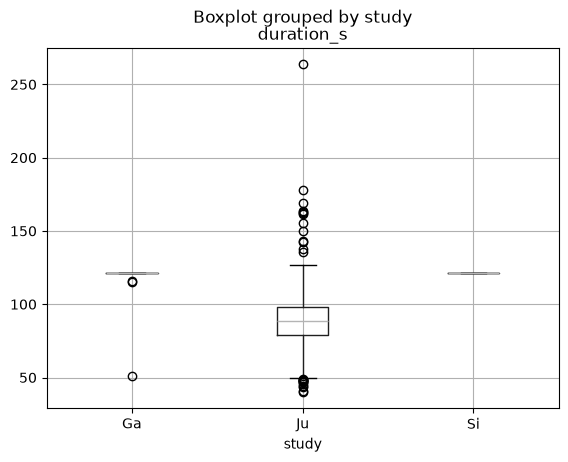

In [8]:
# has null or has_negative should be 0; steady_100hz should equal the number of walks
display(quality_df[['has_nan', 'has_negative', 'steady_100hz']].sum())
# duration by study
display(quality_df.groupby('study')['duration_s'].describe())
quality_df.boxplot(column='duration_s', by='study')

Based on boxplot: As length varies by study rather than presence of Pd, features will be computed based on stride/min to ensure consistency in length instead of original totals. 

In [ ]:
#contingency table of study and group against walk number
quality_df['group'] = quality_df['file'].str[2:4]
quality_df['walk'] = quality_df['file'].str[7:9]
table1 = pd.crosstab(index=[quality_df['study'], quality_df['group']], columns = quality_df['walk'])
print(table1)

table2 = pd.crosstab(index = quality_df['study'], columns = quality_df['group'])
print(table2)

Ju walks 02–07 (cued walking) exist only for PD patients, and Ga walk 10 (dual-task) is mostly PD (21 vs 6). Including them would let the number and type of walks reveal the label, so only normal walks are kept (01, plus Ga 02): 118 PD and 86 control walks from 93 and 72 subjects. Hence, features will only include normal walks to ensure consistency. Apply same filter in list_walks() in data.py.

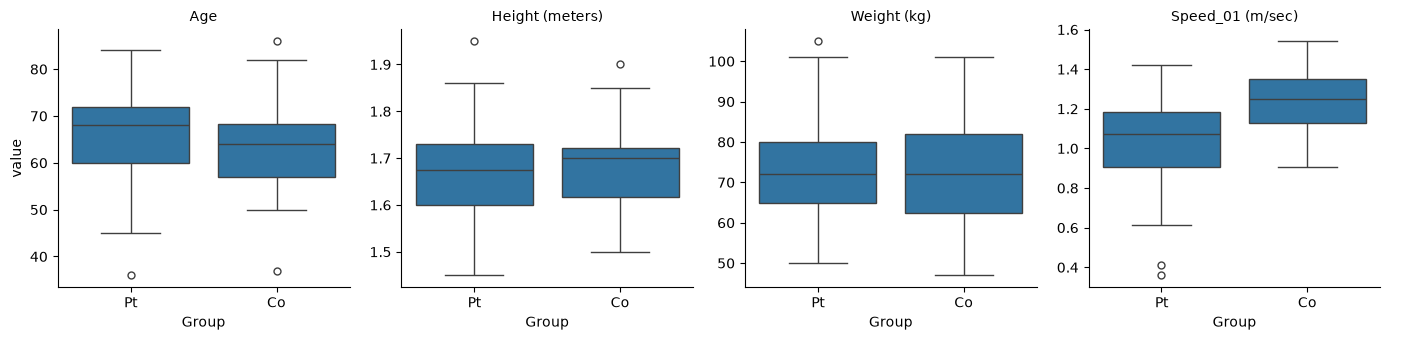

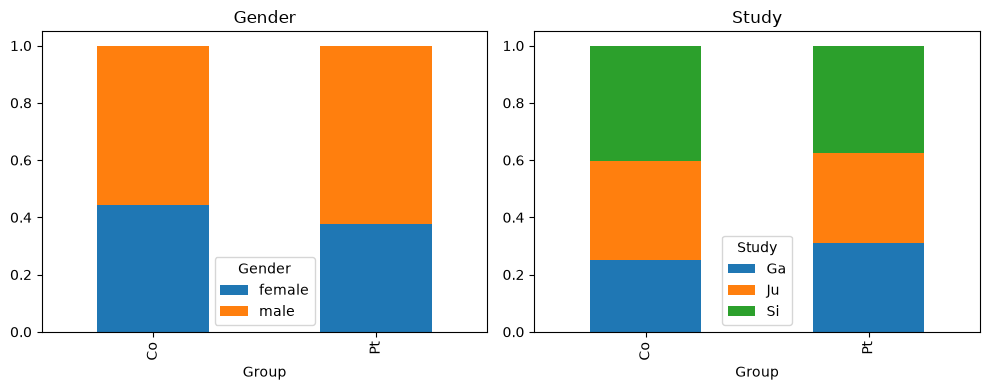

In [ ]:
# finding confounders (things like height/weight may/may not affect both presence of Pd but also walks)

# visual
num_cols = ['Age', 'Height (meters)', 'Weight (kg)', 'Speed_01 (m/sec)']
long_df = metadata_df.melt(id_vars='Group', value_vars=num_cols)
g = sns.catplot(data=long_df, x='Group', y='value', col='variable',
                kind='box', sharey=False, height=3.5)
g.set_titles('{col_name}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pd.crosstab(metadata_df['Group'], metadata_df['Gender'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[0], title='Gender')
pd.crosstab(metadata_df['Group'], metadata_df['Study'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[1], title='Study')
plt.tight_layout()

In [ ]:
# numerical 
from scipy.stats import chi2_contingency
from scipy.stats import mannwhitneyu


chi2, p, dof, expected = chi2_contingency(pd.crosstab(metadata_df['Group'], metadata_df['Gender']))
print(f'Gender: chi2 = {chi2:.2f} \n p = {p:.3f}')

chi2, p, dof, expected = chi2_contingency(pd.crosstab(metadata_df['Group'], metadata_df['Study']))
print(f'Study: chi2 = {chi2:.2f} \n p = {p:.3f}')

pt = metadata_df[metadata_df['Group'] == 'Pt']
co = metadata_df[metadata_df['Group'] == 'Co']
res = mannwhitneyu(pt[num_cols], co[num_cols], nan_policy='omit')

print(metadata_df.groupby('Group')[num_cols].median())          
print(pd.Series(res.pvalue, index=num_cols).round(3))         

Gender: chi2 = 0.52 
 p = 0.469
Study: chi2 = 0.77 
 p = 0.679
        Age  Height (meters)  Weight (kg)  Speed_01 (m/sec)
Group                                                      
Co     64.0            1.700         72.0            1.2485
Pt     68.0            1.675         72.0            1.0750
Age                 0.040
Height (meters)     0.528
Weight (kg)         0.843
Speed_01 (m/sec)    0.000
dtype: float64


Since both categorical data have p > 0.05 both Groups have similar gender/study split. For speed, p < 0.001 which means Pd walk slower which is expected as it is a symptom. 